Now we move to implementing logistics regression from scratch.

To implementing logistic regression from scratch we first need to understand some concepts.

### 1. Binary Classification

In linear regression, our target column is continuous variable. But in logistic regression is used when our target column is binary varable (in can also deal when there is more than 2 types of classification). In binary classification, the target has two possible classes. In titanic dataset the classes were y=0 (dead) and y=1 (alive). Now our logistic model must learn how the input features relate to the probability of belonging to class 1. 

### 2. Linear score: weights and intercept

Just like linear regression, we begin with a linear combination of the features.

For a single feature:

$$z = wx + b$$

For multiple features:

$$z = w_1 x_1 + w_2 x_2 + \cdots + w_p x_p + b$$

Here:

- $x_j$: the $j$-th feature.
- $w_j$: the weight associated with that feature.
- $b$: the intercept.
- $z$: the linear score, also called the logit.

For example, if $w = 1.2$, $b = -3$, and $x = 4$:

$$z = 1.2(4) - 3 = 1.8$$

So far, this is exactly the same type of calculation as linear regression. But we don't use $z$ directly as the predicted probability.



### 3. Sigmoid function

The sigmoid function transforms any real-valued score into a number strictly between 0 and 1.

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

Our predicted probability becomes:

$$\hat{p} = P(y = 1 \mid x) = \sigma(wx + b)$$

So basically we get z value from the linear score $z = wx + b$. then insert it in the sigmoid function to get a probability.

For $z = 1.8$, the probability is approximately $0.858$, or $85.8\%$.

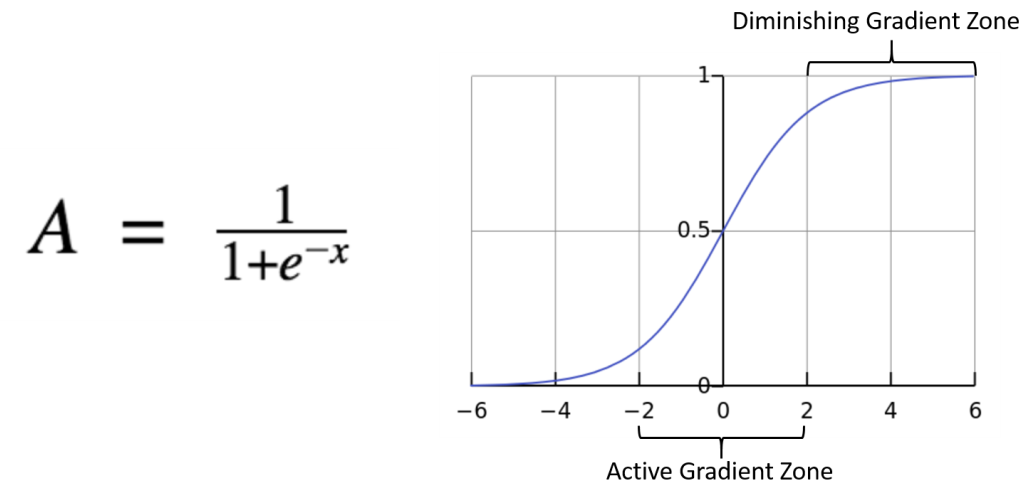

The sigmoid gives us three useful properties:
- If \(z=0\), the predicted probability is \(0.5\).
- If \(z\) is strongly positive, the probability approaches 1.
- If \(z\) is strongly negative, the probability approaches 0.

We now need to convert this probability to binary outcome.

### 4. Probability and Decision Threshold

We got the probabily of a datapoint from the sigmoid function. Now we need to put that data into binary classes. So we assume an arbitrary threshold for classifying the data.
A probability isn't the same thing as a final class prediction.

A common rule is:

$$
\hat{y} =
\begin{cases}
1 & \text{if } \hat{p} \geq 0.5 \\
0 & \text{if } \hat{p} < 0.5
\end{cases}
$$
Here the threshold would be 0.5.

For example:

| Predicted probability | Predicted class |
|:----------------------:|:----------------:|
| 0.15 | 0 |
| 0.49 | 0 |
| 0.50 | 1 |
| 0.87 | 1 |

The threshold of 0.5 is a default, not a universal rule. If missing a disease is especially costly, for example, we might choose a lower threshold to increase sensitivity.

**Why separate probabilities from class predictions?** 

Probabilities retain information about how confident the model is that a datapoint falls to class 1, while a threshold converts them into classification.

### 5. Binary cross-entropy loss/log loss

This is one of the biggest differences from linear regression.

For binary classification, we generally use binary cross-entropy (BCE), also called log loss:

$$
J(w, b) = -\frac{1}{n}\sum_{i=1}^{n}\big[y_i \log(\hat{p}_i) + (1-y_i)\log(1-\hat{p}_i)\big]
$$
where, $\hat{p_i} = \sigma(wx_i + b)$

Let's examine what happens for each class.


If the actual label is $y = 1$, its contribution to the loss is:

$$-\log(\hat{p})$$

If the actual label is $y = 0$, its contribution is:

$$-\log(1-\hat{p})$$

Consider an observation whose true class is 1:

- Predicting $0.95$ produces a small loss.
- Predicting $0.50$ produces a loss of approximately $0.693$.
- Predicting $0.01$ produces a very large loss.

The loss penalizes confident, incorrect predictions heavily.

**Why not use MSE like linear regression?** 

MSE can be used in some classification setups, but BCE is a natural choice for probabilistic binary classification. With a sigmoid output, BCE also produces a particularly convenient gradient.

### 6. Derivatives and Gradients

Our training goal is still to minimize a loss function, so we need gradients for the parameters.

For logistic regression, the result is surprisingly similar to linear regression:

$$
\frac{\partial J}{\partial w} = \frac{1}{n}\sum_{i=1}^{n}(\hat{p}_i - y_i)x_i
$$

$$
\frac{\partial J}{\partial b} = \frac{1}{n}\sum_{i=1}^{n}(\hat{p}_i - y_i)
$$

where, $\hat{p_i} = \sigma(wx_i + b)$

We use these gradients in gradient descent to update the parameters.

### 7. Gradient descent and learning rate

Once we calculate the gradients, we update the parameters:

$$
w_{new} \leftarrow w_{old} - \alpha \frac{\partial J}{\partial w}
$$

$$
b_{new} \leftarrow b_{old} - \alpha \frac{\partial J}{\partial b}
$$

where $\alpha$ is the learning rate.

This is the same gradient descent algorithm you used for linear regression.

The learning rate $\alpha$ controls the size of each update. A very small rate may lead to slow training, while a very large rate may cause the loss to fluctuate or diverge.

### 8. Training loop and convergence

Every iteration follows this sequence:

1. Initialize $w, b$
2. Calculate $z = wx + b$
3. Apply sigmoid to get probabilities
4. Calculate BCE loss and gradients
5. Update $w, b$ using gradient descent
6. Go to step 2

Repeat until the loss stabilizes/the difference between the new and old $w, b$ is small enough or the iteration limit is reached.

This should look familiar: the structure is almost identical to your linear regression training loop. The major differences are the sigmoid prediction and the BCE loss.

### 9. Some types of evaluation

After training, we need to assess the quality of the predictions.

| Metric | Meaning | Formula |
|---|---|---|
| Accuracy | Proportion of predictions that are correct | $\dfrac{TP + TN}{TP + TN + FP + FN}$ |
| Precision | Of the observations predicted positive, how many are actually positive? | $\dfrac{TP}{TP + FP}$ |
| Recall | Of the actual positive observations, how many did the model identify? | $\dfrac{TP}{TP + FN}$ |
| F1-score | Harmonic mean of precision and recall | $2 \cdot \dfrac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$ |
| ROC-AUC | How well the model ranks positive observations above negative ones across thresholds | Area under the ROC curve (True Positive Rate vs. False Positive Rate) |

Where:
- $TP$ = True Positives
- $TN$ = True Negatives
- $FP$ = False Positives
- $FN$ = False Negatives

Accuracy alone can be misleading when one class is much more common than the other. For example, if 95% of patients do not have a disease, a model that always predicts "no disease" achieves 95% accuracy but detects no cases.

#### Now we can implement it in the code 

##### We first need to generate the binary dataset (we will use study hour to pass fail example, so we can understand what's happening more clearly)

In [1]:
import numpy as np 

np.random.seed(42)

X = 10 * np.random.rand(1000) 
# generates 1000 random study hours uniformly spread between [0,10). as np.random.rand() gives uniform distribution
# from [0,1) 

# Now for each study hour we get the true probability of passing. 
true_prob = 1/(1+np.exp(-(-6+1.2*X)))
# the -6 and 1.2 are arbitrary parameters for this model that the model will try to estimate

# Converting the true probability to binary data 
y = (np.random.rand(1000)< true_prob).astype(int)
# here we assign a random number to each student from [0,1). and if the number is less that the true_probablity of 
# passing the number assigned to y will be 1 (as the true prob represents the probability of passing, so a bigger
# true prob should give more passes) otherwise it will be 0. 

##### Now we split the data into training and testing set (the same way we did in the linear regression)

In [2]:
indices = np.random.permutation(len(X))
split = int(0.8 * len(X))

train_idx = indices[:split]
test_idx = indices[split:]

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

##### we initialize the parameters for logistic regression (Here we will also predict w and b as we did with linear regression)

In [3]:
w = 0
b = 0
# these are the initial values of beta and beta0. here beta1=w and beta0=b. we first take 0 as initial value 
learning_rate = 0.01
epochs =3000# the number of repeatation through the dataset

n= len(X_train)

##### Now we train the model inside a for loop

In [4]:
for epoch in range(epochs):
    # first we calculate the linear score 
    z = w *X_train +b 

    # Converting scores into probabilities using sigmoid function
    prob = 1/(1+np.exp(-z))

    # calculating the binary cross-entropy loss 
    # now for calculating the binary cross-entropy loss we would input the values of y into the log() funcion
    # we cannot input 0 in the log function as it will break training 
    # so we have to adjust the values of y so it does not contain 0 or 1 (as we would have log(1-y) in the loss func) 
    # We will clip the values of y 
    # basically we will use the clip() function to do it 
    # np.clip(array, min_val, max_val) 
    # any value in the array which is less than min_val will be replaced by min_val
    # and any value in the array which is greater than max_val will be replaced by max_val 

    eps = 1e-15 # first we have to define a very small number
    # then we will use clip 
    prob_safe = np.clip(prob, eps, 1-eps) # we basically use the very small number as min and 1-that very small number as max

    # now we can calculate the bianry cross-entropy loss function 
    loss = -np.mean(
        y_train *np.log(prob_safe) + (1-y_train)* np.log(1-prob_safe)
    )

    # calculating gradient 
    error = prob- y_train # p_hat - yi part 

    dw = (1/n)* np.sum(error*X_train) 
    db = (1/n) * np.sum(error)

    # updating the parameters 
    w = w-learning_rate*dw 
    b = b-learning_rate*db 

    # monitoring progress 
    if (epoch+1)%600 == 0:
        print(f"Epoch: {epoch+1}, BCE: {loss:.4f}")
    
    

Epoch: 600, BCE: 0.4888
Epoch: 1200, BCE: 0.4203
Epoch: 1800, BCE: 0.3811
Epoch: 2400, BCE: 0.3567
Epoch: 3000, BCE: 0.3403


##### Now we use the model to predict on unseen data (the test data)

In [5]:
# first we have to calculate linear score on test data 
z_test = w*X_test +b 
# converting the linear score to probability 
y_test_prob  = 1/(1+np.exp(-z_test))

# converting the probailities to binary classification predictions 
y_test_pred = (y_test_prob >= 0.5).astype(int) # 0.5 as threshold 

##### Now we need to evaluate the model performance classiying the test data 

| Metric | Meaning | Formula |
|---|---|---|
| Accuracy | Proportion of predictions that are correct | $\dfrac{TP + TN}{TP + TN + FP + FN}$ |
| Precision | Of the observations predicted positive, how many are actually positive? | $\dfrac{TP}{TP + FP}$ |
| Recall | Of the actual positive observations, how many did the model identify? | $\dfrac{TP}{TP + FN}$ |
| F1-score | Harmonic mean of precision and recall | $2 \cdot \dfrac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$ |

In [6]:
accuracy = np.mean(y_test_pred == y_test) 

tp = np.sum((y_test_pred == 1) & (y_test == 1)) # true positive
tn = np.sum((y_test_pred == 0) & (y_test == 0)) # true negative
fp = np.sum((y_test_pred == 1) & (y_test == 0)) # false positive
fn = np.sum((y_test_pred == 0) & (y_test == 1)) # false negative

precision = tp / (tp + fp) if tp + fp > 0 else 0.0
recall = tp / (tp + fn) if tp + fn > 0 else 0.0

f1 = (
    2 * precision * recall / (precision + recall) if precision + recall > 0 else 0.0   
)

print("\nLearned model:")
print(f"logit = {w:.3f} * x + ({b:.3f})")

print("\nTest metrics:")
print(f"Accuracy:  {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall:    {recall:.3f}")
print(f"F1-score:  {f1:.3f}")


Learned model:
logit = 0.590 * x + (-2.645)

Test metrics:
Accuracy:  0.880
Precision: 0.854
Recall:    0.907
F1-score:  0.880


##### Now we fit the model and predict for a new observation

In [7]:
x_new = 5

z_new = w*x_new +b 
prob_new = 1/(1+np.exp(-z_new))
class_new = int(prob_new>=0.5)

print(f"\nStudy hours: {x_new}")
print(f"Probability of passing: {prob_new:.3f}")
print(f"Predicted class: {class_new}")


Study hours: 5
Probability of passing: 0.575
Predicted class: 1
